# Session 3: Bayes, Random Variables, Expectation

*ECE 225A, Module 01 (Probability Review), slides 34-54*

This session has two halves. The first half turns conditional probability from Session 2 into two workhorse tools: the **law of total probability**, which finds a probability by splitting into cases, and **Bayes' rule**, which reverses the direction of a conditional. The second half introduces **random variables**, describes them by a PMF and a CDF, and summarizes them by one number, the **expectation**. It ends with four tools that make expectations easy to compute: tail sums, LOTUS, linearity, and the indicator method.

## Learning objectives

After this session you should be able to:

1. Find a probability by conditioning on a partition (law of total probability) and organize the work as a probability tree.
2. Reverse a conditional probability with Bayes' rule and sanity-check the resulting posteriors.
3. Define a random variable, describe it by its PMF and its CDF, and convert between the two.
4. Compute an expectation from its definition and read it as a long-run average.
5. Compute $E[X]$ for a nonnegative integer variable as a sum of tail probabilities.
6. Compute $E[g(X)]$ with LOTUS and simplify with linearity of expectation.
7. Find the mean of a count with the indicator method.

## Prerequisites

- Counting with $\binom{n}{k}$ and equiprobable spaces (Session 1).
- Conditional probability $P(F \mid E) = P(E \cap F)/P(E)$, the chain rule $P(E \cap F) = P(E)\,P(F \mid E)$, and independence (Session 2).
- Finite and infinite sums, and swapping the order of a double sum whose terms are nonnegative.

In [1]:
from fractions import Fraction
from math import comb
from itertools import product, combinations
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(225)

BLUE, ORANGE, INK, MUTED, FAINT, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#c3c2b7", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})


def show(label, p):
    # Print a probability as an exact fraction and as a decimal.
    print(f"{label}: {p} = {float(p):.6f}")

## 1. The law of total probability (slides 34-35)

**Intuition.** Some probabilities are hard to find in one shot but easy once you know which *case* you are in. Divide and conquer:

1. break the sample space into cases that do not overlap;
2. find the probability of "this case and the event" with the chain rule;
3. add the pieces.

**Formal statement.** For any events $E$ and $F$, the sets $E \cap F$ and $E^c \cap F$ are disjoint and their union is $F$. Adding the two pieces, then applying the chain rule to each,

$$P(F) = P(E \cap F) + P(E^c \cap F) = P(E)\,P(F \mid E) + P(E^c)\,P(F \mid E^c).$$

More generally, if $F_1, \dots, F_k$ form a *partition* of $\Omega$ (pairwise disjoint, with union $\Omega$), then for every event $D$

$$P(D) = \sum_{i=1}^{k} P(F_i \cap D) = \sum_{i=1}^{k} P(F_i)\,P(D \mid F_i).$$

The right side is a weighted average of the conditional probabilities $P(D \mid F_i)$, with weights $P(F_i)$ that add to 1. So $P(D)$ always lies between the smallest and the largest $P(D \mid F_i)$.

**Example (a check on two dice).** The slides state the law without numbers, so here is a check on a space small enough to list. Roll two dice, let $E$ = "the first die is even" and $F$ = "the sum is 8".

- If the first die is 2, 4, or 6, the second must be 6, 4, or 2: 3 of these 18 outcomes, so $P(F \mid E) = 1/6$.
- If the first die is 1, 3, or 5, the second must be 7 (impossible), 5, or 3: 2 of 18, so $P(F \mid E^c) = 1/9$.
- $P(F) = \frac{1}{2} \cdot \frac{1}{6} + \frac{1}{2} \cdot \frac{1}{9} = \frac{3}{36} + \frac{2}{36} = \frac{5}{36}$, which matches the direct count of $\lbrace (2,6), (3,5), (4,4), (5,3), (6,2) \rbrace$.

**Python check.** Enumerate the 36 equally likely ordered pairs and compute both sides.

In [2]:
dice = list(product(range(1, 7), repeat=2))   # 36 equally likely ordered pairs


def P(event):
    return Fraction(sum(event(w) for w in dice), len(dice))


def P_given(event, cond):
    return P(lambda w: event(w) and cond(w)) / P(cond)


first_even = lambda w: w[0] % 2 == 0           # E
first_odd = lambda w: not first_even(w)        # E^c
sum_is_8 = lambda w: w[0] + w[1] == 8          # F

show("direct            P(F)", P(sum_is_8))
show("total probability P(F)", P(first_even) * P_given(sum_is_8, first_even)
                                 + P(first_odd) * P_given(sum_is_8, first_odd))

direct            P(F): 5/36 = 0.138889
total probability P(F): 5/36 = 0.138889


## 2. Example: defective phones and the probability tree (slide 36)

**Setup.** A phone maker uses three factories. Let $F_i$ = "the phone was made by factory $i$" and $D$ = "the phone is defective". Every phone comes from exactly one factory, so $F_1, F_2, F_3$ partition $\Omega$.

| Factory | Share $P(F_i)$ | Defect rate $P(D \mid F_i)$ | Joint $P(F_i \cap D)$ |
|---|---|---|---|
| 1 | 50% | 4% | $0.5 \times 0.04 = 0.02$ |
| 2 | 30% | 10% | $0.3 \times 0.10 = 0.03$ |
| 3 | 20% | 5% | $0.2 \times 0.05 = 0.01$ |

**Step by step.**

1. Split by factory: $P(D) = P(F_1 \cap D) + P(F_2 \cap D) + P(F_3 \cap D)$.
2. Chain rule on each piece: $P(F_i \cap D) = P(F_i)\,P(D \mid F_i)$, giving 0.02, 0.03, 0.01.
3. Add: $P(D) = 0.02 + 0.03 + 0.01 = 0.06$.

So 6% of all phones are defective. As a weighted average, 6% sits between the lowest factory rate (4%) and the highest (10%).

In earlier examples, splitting into cases was a convenience. Here it is a necessity: the data only describe defect rates *within* each factory, so conditioning on the factory is the only way to use them.

In [3]:
factories = ["F1", "F2", "F3"]
prior = {"F1": Fraction(1, 2), "F2": Fraction(3, 10), "F3": Fraction(1, 5)}
p_def = {"F1": Fraction(4, 100), "F2": Fraction(10, 100), "F3": Fraction(5, 100)}

joint = {f: prior[f] * p_def[f] for f in factories}   # chain rule: P(F_i and D)
P_D = sum(joint.values())                              # law of total probability
for f in factories:
    show(f"P({f} and D) = {prior[f]} * {p_def[f]}", joint[f])
show("P(D)", P_D)

P(F1 and D) = 1/2 * 1/25: 1/50 = 0.020000
P(F2 and D) = 3/10 * 1/10: 3/100 = 0.030000
P(F3 and D) = 1/5 * 1/20: 1/100 = 0.010000
P(D): 3/50 = 0.060000


**The probability tree.** A tree draws the same computation. The first level branches on the factory and is labeled with $P(F_i)$; the second level branches on defective ($D$) or not ($D^c$) and is labeled with the *conditional* probability given that factory. Multiplying along a path gives the probability of its leaf (chain rule), and adding the leaves that make up an event gives the probability of the event (total probability). The blue paths are the three ways a phone can end up defective.

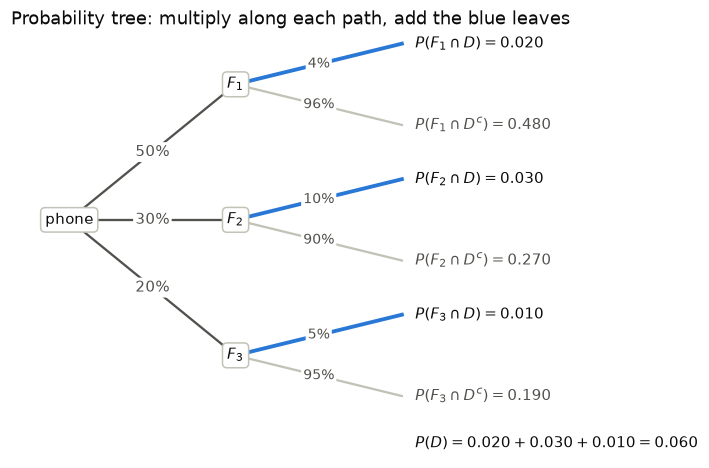

In [4]:
def draw_tree(ax, prior, p_def):
    # Level 1: factory, labeled P(F_i). Level 2: D or D^c, labeled P(. | F_i).
    # Each leaf shows its path product. Defective paths are blue.
    node = dict(boxstyle="round,pad=0.3", fc="white", ec=FAINT)
    tag = dict(boxstyle="round,pad=0.15", fc="white", ec="none")
    ax.text(0, 0, "phone", ha="center", va="center", color=INK, bbox=node, zorder=3)
    for i, (f, y) in enumerate(zip(prior, [2.0, 0.0, -2.0]), start=1):
        ax.plot([0, 1], [0, y], color=MUTED, lw=1.5, zorder=1)
        ax.text(0.5, y / 2, f"{float(prior[f]):.0%}", ha="center", va="center", color=MUTED, bbox=tag, zorder=2)
        ax.text(1, y, f"$F_{i}$", ha="center", va="center", color=INK, bbox=node, zorder=3)
        for hot, dy, p in [(True, 0.6, p_def[f]), (False, -0.6, 1 - p_def[f])]:
            ax.plot([1, 2], [y, y + dy], color=BLUE if hot else FAINT, lw=2.5 if hot else 1.5, zorder=1)
            ax.text(1.5, y + dy / 2, f"{float(p):.0%}", ha="center", va="center",
                    color=MUTED, bbox=tag, fontsize=9, zorder=2)
            leaf = "D" if hot else "D^c"
            ax.text(2.08, y + dy, rf"$P(F_{i} \cap {leaf}) = {float(prior[f] * p):.3f}$",
                    ha="left", va="center", color=INK if hot else MUTED)
    ax.set_xlim(-0.35, 3.75)
    ax.set_ylim(-3.5, 2.75)
    ax.set_axis_off()


fig, ax = plt.subplots(figsize=(8, 5))
draw_tree(ax, prior, p_def)
ax.text(2.08, -3.3, r"$P(D) = 0.020 + 0.030 + 0.010 = 0.060$", ha="left", va="center", color=INK)
ax.set_title("Probability tree: multiply along each path, add the blue leaves", color=INK, loc="left")
plt.show()

**Monte Carlo check.** Simulate a million phones: pick a factory with the given shares, then make the phone defective with that factory's rate. The fraction of defective phones should be close to 0.06.

In [5]:
N_PHONES = 1_000_000
factory = rng.choice(3, size=N_PHONES, p=[0.5, 0.3, 0.2])               # 0, 1, 2 stand for F1, F2, F3
defective = rng.random(N_PHONES) < np.array([0.04, 0.10, 0.05])[factory]
print(f"P(D): simulated {defective.mean():.4f}   exact {float(P_D):.4f}")

P(D): simulated 0.0599   exact 0.0600


## 3. Bayes' rule (slides 37-38)

**Intuition.** Conditional probabilities often arrive in the "wrong" direction. Data are usually collected from cause to effect: a factory's defect rate is $P(\text{defective} \mid \text{factory})$. After the fact we see the effect and ask about the cause: $P(\text{factory} \mid \text{defective})$. Bayes' rule runs the conditioning backward. It turns $P(F \mid E)$ into $P(E \mid F)$, using a bit more information: $P(E)$ and $P(F)$.

**Formal statement.** For events $E, F$ with $P(F) > 0$,

$$P(E \mid F) = \frac{P(E)\,P(F \mid E)}{P(F)}.$$

**Proof.** Write the intersection two ways using the definition of conditional probability, $P(E \cap F) = P(F)\,P(E \mid F) = P(E)\,P(F \mid E)$, and divide by $P(F)$.

The denominator $P(F)$ is rarely given directly. Compute it by total probability over a partition $E_1, \dots, E_k$:

$$P(E_i \mid F) = \frac{P(E_i)\,P(F \mid E_i)}{\sum_{j=1}^{k} P(E_j)\,P(F \mid E_j)}.$$

Vocabulary: $P(E_i)$ is the **prior** (belief before seeing $F$), $P(F \mid E_i)$ is the **likelihood** (how well $E_i$ explains $F$), and $P(E_i \mid F)$ is the **posterior** (belief after seeing $F$). In words: posterior is proportional to prior times likelihood.

**Check on two dice.** With $E$ = "first die even" and $F$ = "sum is 8" from Section 1,

$$P(E \mid F) = \frac{P(E)\,P(F \mid E)}{P(F)} = \frac{\frac{1}{2} \cdot \frac{1}{6}}{5/36} = \frac{3}{5}.$$

Directly: of the 5 outcomes with sum 8, three, namely $(2,6), (4,4), (6,2)$, have an even first die.

In [6]:
show("Bayes  P(E | F)", P(first_even) * P_given(sum_is_8, first_even) / P(sum_is_8))
show("direct P(E | F)", P_given(first_even, sum_is_8))

Bayes  P(E | F): 3/5 = 0.600000
direct P(E | F): 3/5 = 0.600000


## 4. Example: which factory made the defective phone? (slide 39)

**Question.** You buy a phone and it turns out to be defective. What is the probability that it was made by each factory?

**Step by step.** Apply Bayes' rule with the partition $F_1, F_2, F_3$ and $P(D) = 0.06$ from Section 2:

$$P(F_1 \mid D) = \frac{P(F_1)\,P(D \mid F_1)}{P(D)} = \frac{0.5 \cdot 0.04}{0.06} = \frac{0.02}{0.06} = \frac{1}{3},$$

$$P(F_2 \mid D) = \frac{0.3 \cdot 0.1}{0.06} = \frac{0.03}{0.06} = \frac{1}{2}, \qquad P(F_3 \mid D) = \frac{0.2 \cdot 0.05}{0.06} = \frac{0.01}{0.06} = \frac{1}{6}.$$

On the tree: keep only the blue leaves (2%, 3%, and 1% of all phones) and rescale them so they add to 1. Each posterior is that leaf's share of the 6%.

**Three sanity checks.**

1. **They add to 1:** $\frac{1}{3} + \frac{1}{2} + \frac{1}{6} = 1$, as they must, since a defective phone came from some factory.
2. **They are proportional to the joint probabilities** $P(F_i \cap D) = 2\%, 3\%, 1\%$, which total 6%: the posteriors are $2/6, 3/6, 1/6$.
3. **$P(F_i \mid D)$ grows with both $P(F_i)$ and $P(D \mid F_i)$.** A bigger factory makes more phones of every kind, and a sloppier factory makes more defects. Factory 2 makes only 30% of the phones but half of the defective ones, because its defect rate is the highest.

In [7]:
posterior = {f: joint[f] / P_D for f in factories}
for f in factories:
    show(f"P({f} | D)", posterior[f])
assert sum(posterior.values()) == 1

P(F1 | D): 1/3 = 0.333333
P(F2 | D): 1/2 = 0.500000
P(F3 | D): 1/6 = 0.166667


**Monte Carlo check.** Among the simulated defective phones from Section 2, count the share made by each factory.

In [8]:
for i, f in enumerate(factories):
    print(f"P({f} | D): simulated {np.mean(factory[defective] == i):.4f}   exact {float(posterior[f]):.4f}")

P(F1 | D): simulated 0.3351   exact 0.3333
P(F2 | D): simulated 0.4976   exact 0.5000
P(F3 | D): simulated 0.1673   exact 0.1667


The chart compares beliefs before and after seeing the defect. Learning that the phone is defective moves probability away from the large but careful factory 1 and toward factory 2.

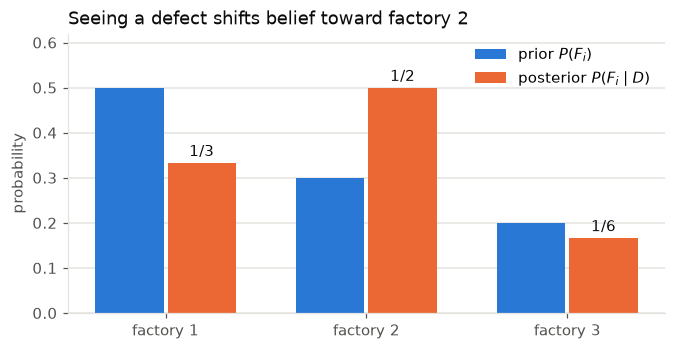

In [9]:
x = np.arange(3)
w = 0.34
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.bar(x - w / 2 - 0.01, [float(prior[f]) for f in factories], width=w, color=BLUE, label=r"prior $P(F_i)$")
ax.bar(x + w / 2 + 0.01, [float(posterior[f]) for f in factories], width=w, color=ORANGE,
       label=r"posterior $P(F_i \mid D)$")
for xi, f in zip(x, factories):
    ax.text(xi + w / 2 + 0.01, float(posterior[f]) + 0.015, str(posterior[f]), ha="center", color=INK)
ax.set_xticks(x, ["factory 1", "factory 2", "factory 3"])
ax.grid(axis="x", visible=False)
ax.set(ylim=(0, 0.62), ylabel="probability")
ax.legend(frameon=False, loc="upper right")
ax.set_title("Seeing a defect shifts belief toward factory 2", color=INK, loc="left")
plt.show()

## 5. Random variables (slide 40)

**Intuition.** A random variable is a random experiment whose outcome is a number. Most experiments we care about produce numbers: a die roll, a count of heads, the number of defective phones in a shipment, a waiting time. Even when the raw outcome is not a number (a poker hand), we usually care about a number attached to it (how many aces it holds). Working with numbers has four advantages:

- **Specify:** a distribution can be given by a table or a formula over numbers.
- **Visualize:** probabilities can be plotted against the number line.
- **Functions:** new random variables come for free, such as $X^2$, $|X - 1|$, or $2^X$.
- **Operations:** random variables can be added, averaged, and compared, as in $X + Y$, and summarized by numbers such as the mean.

**Formal definition.** A random variable $X$ on a sample space $\Omega$ assigns a real number $X(\omega)$ to each outcome $\omega \in \Omega$. Uppercase $X$ denotes the random variable and lowercase $x$ a particular value. The event "$X = x$" is the set $\lbrace \omega : X(\omega) = x \rbrace$.

There are two main **types**. A *discrete* random variable takes finitely or countably many values, and is the subject of this session. A *continuous* random variable spreads its probability over an interval; it appears in Session 5.

**Example.** Roll two dice, so $\Omega$ is the 36 equally likely ordered pairs. Many random variables live on the same $\Omega$, for example the sum $S(a, b) = a + b$ and the maximum $M(a, b) = \max(a, b)$. The event $\lbrace S = 4 \rbrace = \lbrace (1,3), (2,2), (3,1) \rbrace$ has probability $3/36$.

In [10]:
S = lambda w: w[0] + w[1]   # sum of the two dice
M = lambda w: max(w)        # larger of the two dice

for w in [(1, 3), (2, 2), (6, 5)]:
    print(f"outcome {w}:  S = {S(w):2d},  M = {M(w)}")
print("event {S = 4} =", [w for w in dice if S(w) == 4])
show("P(S = 4)", P(lambda w: S(w) == 4))

outcome (1, 3):  S =  4,  M = 3
outcome (2, 2):  S =  4,  M = 2
outcome (6, 5):  S = 11,  M = 6
event {S = 4} = [(1, 3), (2, 2), (3, 1)]
P(S = 4): 1/12 = 0.083333


## 6. PMF and CDF (slide 41)

**Intuition.** There are two standard ways to describe the distribution of a discrete random variable. The PMF answers "how likely is *exactly* $x$?"; the CDF answers "how likely is *at most* $x$?". Each one determines the other.

**Formal definitions.**

- The **probability mass function** (PMF) is $p(x) = P(X = x)$, the probability *of* $x$. It satisfies $p(x) \ge 0$ and $\sum_x p(x) = 1$.
- The **cumulative distribution function** (CDF) is

$$F(x) = P(X \le x) = P\big(X \in (-\infty, x]\big) = \sum_{u \le x} p(u),$$

the probability *up to* $x$. Even when $X$ is discrete, $F$ is defined for every real $x$.

For a discrete $X$, the CDF is a staircase:

- it is nondecreasing, tends to 0 as $x \to -\infty$ and to 1 as $x \to \infty$;
- it is flat between consecutive values of $X$ and jumps by exactly $p(x)$ at each value $x$;
- at a jump, $F(x)$ already includes the jump (the function is right-continuous), while $P(X < x)$ is the level just to the left;
- interval probabilities are differences: $P(a < X \le b) = F(b) - F(a)$.

**Example (sum of two dice).** Go from the PMF to the CDF with running sums, evaluate $F$ at points that are not values of $S$, and come back to the PMF from the jumps.

In [11]:
def pmf_of(rv, space=dice):
    # PMF of a random variable on an equiprobable space, as {value: probability}.
    counts = Counter(rv(w) for w in space)
    return {x: Fraction(c, len(space)) for x, c in sorted(counts.items())}


def cdf(pmf, x):
    return sum((p for v, p in pmf.items() if v <= x), Fraction(0))


pmf_S = pmf_of(S)
print("PMF of S:", {x: str(p) for x, p in pmf_S.items()})
for x in [-3, 2, 4, 4.5, 6.99, 7, 100]:
    print(f"F({x}) = {cdf(pmf_S, x)}")

PMF of S: {2: '1/36', 3: '1/18', 4: '1/12', 5: '1/9', 6: '5/36', 7: '1/6', 8: '5/36', 9: '1/9', 10: '1/12', 11: '1/18', 12: '1/36'}
F(-3) = 0
F(2) = 1/36
F(4) = 1/6
F(4.5) = 1/6
F(6.99) = 5/12
F(7) = 7/12
F(100) = 1


In [12]:
# Back from the CDF to the PMF: S has integer values, so the jump at x is F(x) - F(x - 1).
jumps = {x: cdf(pmf_S, x) - cdf(pmf_S, x - 1) for x in range(2, 13)}
assert jumps == pmf_S
show("P(4 < S <= 7) = F(7) - F(4)", cdf(pmf_S, 7) - cdf(pmf_S, 4))
show("P(S < 7) = F(6)            ", cdf(pmf_S, 6))

P(4 < S <= 7) = F(7) - F(4): 5/12 = 0.416667
P(S < 7) = F(6)            : 5/12 = 0.416667


## 7. Example: Bernoulli(0.7) PMF and CDF (slide 42)

**Intuition.** The simplest random variable takes only the values 0 and 1. It models any yes/no outcome: success or failure, defective or not, heads or tails. The Bernoulli variable $B_{0.7}$ equals 1 with probability 0.7.

**PMF and CDF, step by step.**

$$p(x) = \begin{cases} 0.3 & x = 0, \\ 0.7 & x = 1, \\ 0 & x \ne 0, 1, \end{cases} \qquad F(x) = \begin{cases} 0 & x < 0, \\ 0.3 & 0 \le x < 1, \\ 1 & 1 \le x. \end{cases}$$

- To the left of 0 there is no mass yet, so $F = 0$.
- At 0, $F$ jumps by $p(0) = 0.3$ and stays flat until 1.
- At 1, $F$ jumps by $p(1) = 0.7$ up to 1, and stays there.

So $F(-5) = 0$, $F(0.5) = 0.3$, and $F(17) = 1$: the CDF is defined everywhere even though $X$ has only two values. In the plot, a filled dot marks the value $F$ takes at a jump and an open dot marks the level just to the left.

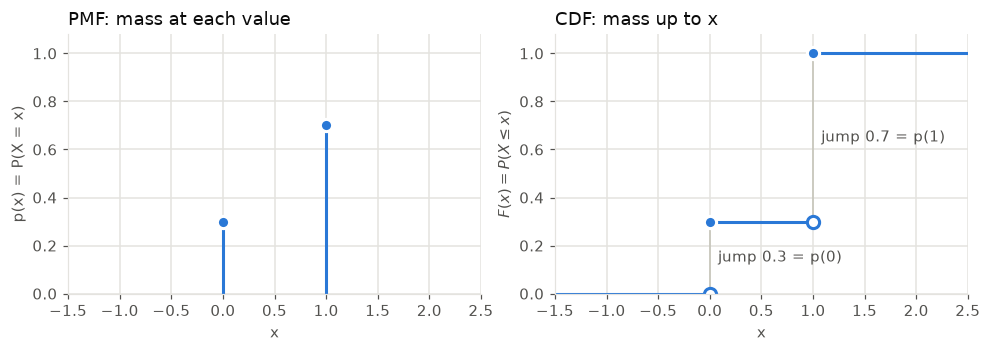

In [13]:
p = Fraction(7, 10)
pmf_B = {0: 1 - p, 1: p}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.3))
xs, ps = list(pmf_B), [float(q) for q in pmf_B.values()]
ax1.vlines(xs, 0, ps, color=BLUE, lw=2)
ax1.plot(xs, ps, "o", color=BLUE, ms=8, mec="white", mew=2)
ax1.set(xlim=(-1.5, 2.5), ylim=(0, 1.08), xlabel="x", ylabel="p(x) = P(X = x)")
ax1.set_title("PMF: mass at each value", color=INK, loc="left")

for a, b, level in [(-1.5, 0, 0), (0, 1, 0.3), (1, 2.5, 1)]:
    ax2.plot([a, b], [level, level], color=BLUE, lw=2)
ax2.vlines([0, 1], [0, 0.3], [0.3, 1], color=FAINT, lw=1)
ax2.plot([0, 1], [0, 0.3], "o", color="white", ms=8, mec=BLUE, mew=2)   # level just to the left
ax2.plot([0, 1], [0.3, 1], "o", color=BLUE, ms=8, mec="white", mew=2)   # F includes the jump
ax2.text(0.08, 0.15, "jump 0.3 = p(0)", va="center", color=MUTED)
ax2.text(1.08, 0.65, "jump 0.7 = p(1)", va="center", color=MUTED)
ax2.set(xlim=(-1.5, 2.5), ylim=(0, 1.08), xlabel="x", ylabel=r"$F(x) = P(X \leq x)$")
ax2.set_title("CDF: mass up to x", color=INK, loc="left")
plt.tight_layout()
plt.show()

**Monte Carlo check.** Draw 100,000 samples of $B_{0.7}$ and compare the fraction of samples at most $t$ with $F(t)$, including points between the values.

In [14]:
samples = (rng.random(100_000) < 0.7).astype(int)
for t in [-0.5, 0, 0.5, 1, 2]:
    print(f"F({t:4}): simulated {np.mean(samples <= t):.4f}   exact {float(cdf(pmf_B, t)):.4f}")

F(-0.5): simulated 0.0000   exact 0.0000
F(   0): simulated 0.2994   exact 0.3000
F( 0.5): simulated 0.2994   exact 0.3000
F(   1): simulated 1.0000   exact 1.0000
F(   2): simulated 1.0000   exact 1.0000
